# Large-scale Synthetic Iris Generation for Few-shot Recognition
## Notebook 07: Baseline Recognition Model

### Objective

This notebook establishes the **baseline performance against which the synthetic-data approach will be compared**.

It trains iris recognition models **without any synthetic images**, using only the real few-shot support images from Notebook 06, and evaluates them on unseen identities.

The notebook must:

1. Train recognition models on the real `train / support` images only.
2. Support the candidate backbones **ResNet50**, **EfficientNet**, and **ViT**.
3. Use the **ArcFace** loss.
4. Evaluate on validation / test identities that were never seen in training, and on a second dataset (cross-dataset).
5. Produce the three requested outputs: **Baseline Accuracy**, **Baseline ROC**, and **Baseline EER**.

### Important boundary of this notebook

This notebook performs **baseline training and evaluation only**.

It does **not** use or generate synthetic images, learn identity/appearance latents (Notebook 08), train a generator (Notebook 09), or use the Triplet and Center losses (Notebook 13). The same evaluation protocol defined here is reused unchanged by the later notebooks, which is what makes the final comparison fair.

### Two baseline variants (both still use real images only)

| Variant | Meaning | Corresponds to the proposal's |
|---|---|---|
| `real_only` | Train on the real support images exactly as they are | Baseline 1: real data only |
| `real_traditional_aug` | Same, plus rotation (circular shift), brightness / contrast, blur and noise augmentation | Baseline 2: traditional augmentation |

Showing both matters: if the synthetic-data model is only compared with a model that uses no augmentation at all, part of its gain could come from augmentation in general rather than from the synthetic identities.

## 1. Research rationale and evaluation protocol

### 1.1 What is trained, and on what

For each shot count `K` in {1, 2, 3, 5}, a separate model is trained on the `K` real support images of every **training** class (`train / support` from Notebook 06). Nothing else is used for learning:

- `train / query`, `val`, and `test` images are never used to update weights.
- `val` (unseen people) is used only to pick the best epoch.
- `test` (unseen people) is evaluated **once**, with the best-validation checkpoint, after training has finished.

By default the model is trained on **CASIA-Iris-Thousand only** (`TRAIN_DATASETS`). IITD is then a genuinely unseen *dataset*, which gives the cross-dataset baseline needed in Notebook 14 for free.

### 1.2 Why embeddings and not a classifier

The goal is recognition of **identities not seen in training**. A classifier over the training identities cannot name a new person, so the network is trained with ArcFace to produce an embedding, and recognition is done by comparing embeddings:

- **Gallery / enrollment**: the `K` support images of each class. Their embeddings are averaged into one *prototype* per class.
- **Probes**: the query images.
- **Score**: cosine similarity between a probe embedding and a class prototype.

### 1.3 Metrics

| Metric | Definition |
|---|---|
| **Rank-1 accuracy** | A probe is correct if its most similar prototype, among **all** classes of the evaluation set, is its own class. |
| **5-way K-shot accuracy** | Same, but only among 5 randomly chosen classes per episode (600 episodes, fixed seed). This is the number the proposal's accuracy table refers to. Reported with a 95% interval. |
| **Macro F1** | F1 of the Rank-1 predictions, averaged over classes. |
| **ROC / AUC** | Genuine scores = probe vs. its own prototype. Impostor scores = probe vs. every other prototype. |
| **EER** | The error rate where false accept rate equals false reject rate. Lower is better. |
| **TAR @ FAR** | True accept rate at fixed false accept rates of 1e-2 and 1e-3. Reported as `NaN` when there are too few impostor scores to resolve that FAR. |

All evaluation episodes and impostor sub-samples use a fixed `EVAL_SEED`, so the baseline and every later model are scored on **exactly the same episodes**.

### 1.4 ArcFace

For an embedding at angle `theta` to its class weight, ArcFace penalizes the target class with an additive angular margin `m` and scales by `s`:

```text
logit_target = s * cos(theta + m)        logit_other = s * cos(theta)
```

so the model must separate identities by a margin on the hypersphere, which is what makes embeddings of unseen identities comparable.

### 1.5 Backbones and inputs

- **ResNet50** and **EfficientNet** are fully convolutional and take the 64 x 512 iris strip directly (the grayscale channel is repeated 3 times).
- **ViT (vit_b_16)** needs a fixed square input, so the strip is resized to 224 x 224. This distorts the aspect ratio; it is applied identically to every ViT model, so comparisons stay fair.
- Weights start from **ImageNet-pretrained** values when they can be downloaded (stored in `pretrained_models/torch_hub`). If the download fails the notebook falls back to random initialization, says so loudly, and records `pretrained_loaded` in the results so such runs are never mixed up with pretrained ones.

### 1.6 Things to keep in mind

- **Run time.** 3 backbones x 4 shots x 2 variants = 24 training runs. This is comfortable on a CUDA GPU and impractical on a CPU. Trim `BACKBONES`, `VARIANTS`, or `SHOTS_TO_RUN`, or start with `QUICK_TEST = True`.
- **One support draw.** The support images were drawn once in Notebook 06. Training seeds measure training randomness, not the effect of *which* images were drawn.
- **Flip augmentation is off.** The proposal lists "flip", but a mirrored iris is not a real view of the same eye, so labelling it with the same identity adds label noise. Set `AUG_HFLIP_PROB = 0.5` to follow the proposal literally.

In [1]:
# ============================================================
# 2. Imports
# ============================================================

import os

# Windows: PyTorch and NumPy can each load their own copy of the OpenMP runtime, and the
# second copy aborts the process at the first NumPy matrix multiplication (the notebook
# kernel "dies"). This must be set BEFORE NumPy / PyTorch are imported.
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import copy
import hashlib
import json
import math
import random
import time
import warnings
import zlib
from pathlib import Path

# PyTorch is imported first on purpose: on Windows, importing it before NumPy / pandas / OpenCV
# avoids DLL-loading conflicts between those libraries.
try:
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
    import torchvision
    from torchvision import models as tv_models
    from torchvision.transforms import functional as tv_F
except ImportError as error:
    raise ImportError(
        "Notebook 07 needs PyTorch and torchvision. Install them in the "
        "'Synthetic Iris' environment, e.g. `pip install torch torchvision` "
        "(use the CUDA build from pytorch.org if you have an NVIDIA GPU)."
    ) from error

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

warnings.filterwarnings("ignore")

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("OpenCV version:", cv2.__version__)
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)

PyTorch version: 2.14.1+cu130
Torchvision version: 0.29.1+cu130
OpenCV version: 5.0.0
NumPy version: 2.4.6
Pandas version: 3.0.5


In [2]:
# ============================================================
# 3. Project paths (inputs)
# ============================================================

NOTEBOOK_DIR = Path.cwd()

if (NOTEBOOK_DIR / "datasets").exists():
    PROJECT_ROOT = NOTEBOOK_DIR
elif (NOTEBOOK_DIR.parent / "datasets").exists():
    PROJECT_ROOT = NOTEBOOK_DIR.parent
else:
    raise FileNotFoundError(
        "Could not locate project root. Run this notebook from "
        "the project root or the notebooks directory."
    )

NOTEBOOK06_RESULTS_DIR = PROJECT_ROOT / "results" / "fewshot_dataset"
MANIFEST_LONG_PATH = NOTEBOOK06_RESULTS_DIR / "manifests" / "fewshot_manifest_long.csv"
FEWSHOT_SPLIT_CONFIG_PATH = NOTEBOOK06_RESULTS_DIR / "split_config.json"

PRETRAINED_DIR = PROJECT_ROOT / "pretrained_models"
PRETRAINED_DIR.mkdir(parents=True, exist_ok=True)

# ImageNet weights downloaded by torchvision are kept inside the project.
torch.hub.set_dir(str(PRETRAINED_DIR / "torch_hub"))

print("Project root:", PROJECT_ROOT)
print("Notebook 06 few-shot dataset:", NOTEBOOK06_RESULTS_DIR)
print("Pretrained weights cache:", PRETRAINED_DIR / "torch_hub")

Project root: E:\Research\LargeScale_Synthetic_Iris_Generation
Notebook 06 few-shot dataset: E:\Research\LargeScale_Synthetic_Iris_Generation\results\fewshot_dataset
Pretrained weights cache: E:\Research\LargeScale_Synthetic_Iris_Generation\pretrained_models\torch_hub


## 4. Configuration

Every setting that can change a result is here and is folded into a **configuration fingerprint**. A finished run is skipped on re-run only if its stored fingerprint matches the current one, so changing a hyperparameter can never silently reuse stale results.

- `QUICK_TEST = True` shrinks the experiment (one backbone, one variant, few epochs, few classes) to check that everything works on your machine **before** a long run. Quick-test outputs go to a separate folder and never mix with real results.
- `TRAIN_DATASETS` decides which dataset(s) the models learn from. Every other dataset becomes a cross-dataset evaluation.
- `SELECTION_METRIC` decides which validation metric picks the best epoch.

In [3]:
# ============================================================
# 4. Configuration
# ============================================================

QUICK_TEST = False          # True = tiny smoke test, written to a separate folder

# ---- what to run ----
BACKBONES = ["resnet50", "efficientnet_b0", "vit_b_16"]
VARIANTS = ["real_only", "real_traditional_aug"]
SHOTS_TO_RUN = [1, 2, 3, 5]
SEEDS = [42]
TRAIN_DATASETS = ["CASIA-Iris-Thousand"]

# ---- model ----
USE_PRETRAINED = True       # ImageNet initialisation (falls back loudly if unavailable)
EMBEDDING_DIM = 256
INPUT_HW = (64, 512)        # size of the normalized iris textures from Notebook 03
VIT_INPUT_SIZE = 224        # ViT needs a square input

# ---- ArcFace ----
ARC_SCALE = 30.0
ARC_MARGIN = 0.5

# ---- optimisation ----
EPOCHS = 60
BATCH_SIZE = 64
BASE_LR_PRETRAINED = {"resnet50": 1e-4, "efficientnet_b0": 3e-4, "efficientnet_b3": 3e-4, "vit_b_16": 3e-5}
BASE_LR_SCRATCH = 1e-3
HEAD_LR_MULT = 10.0         # embedding layer and ArcFace weights learn faster than the backbone
WEIGHT_DECAY = 1e-4
WARMUP_EPOCHS = 1
GRAD_CLIP = 5.0
MIXED_PRECISION = True      # used only on CUDA

# ---- model selection (validation identities only) ----
EVAL_EVERY = 2              # epochs between validation evaluations
EARLY_STOP_PATIENCE = 8     # evaluations without improvement before stopping
SELECTION_METRIC = "eer"    # "eer" (lower is better) or "rank1" (higher is better)

# ---- traditional augmentation (real_traditional_aug only) ----
AUG_MAX_SHIFT = 32          # +/- pixels of the 512-wide strip (about +/- 22 degrees of iris rotation)
AUG_BRIGHTNESS = 0.2
AUG_CONTRAST = 0.2
AUG_BLUR_PROB = 0.3
AUG_NOISE_PROB = 0.3
AUG_NOISE_STD = 0.04
AUG_HFLIP_PROB = 0.0        # see section 1.6 for why this is off

# ---- evaluation ----
EVAL_SEED = 2024            # fixed so every notebook scores the same episodes
EPISODE_WAY = 5
NUM_EPISODES = 600
MAX_IMPOSTOR_SCORES = 5_000_000
FAR_TARGETS = [1e-2, 1e-3]
CROSS_DATASET_USE_ALL_SPLITS = True   # a dataset never seen in training can be used in full
EVALUATE_TRAIN_CLOSED_SET = True      # diagnostic: training people, held-out query images

# ---- bookkeeping ----
MAX_TRAIN_CLASSES = None    # e.g. 100 to limit training classes for a trial
RESUME = True
SAVE_CHECKPOINTS = True     # about 100 MB (ResNet50) to 350 MB (ViT) per run

if QUICK_TEST:
    BACKBONES = ["resnet50"]
    VARIANTS = ["real_only"]
    SHOTS_TO_RUN = [1, 3]
    EPOCHS = 3
    EVAL_EVERY = 1
    MAX_TRAIN_CLASSES = 60
    NUM_EPISODES = 100
    print("QUICK_TEST is ON: tiny experiment, separate output folder.")

# ---- sanity checks on the configuration itself ----
KNOWN_BACKBONES = {"resnet50": 2048, "efficientnet_b0": 1280, "efficientnet_b3": 1536, "vit_b_16": 768}
for name in BACKBONES:
    assert name in KNOWN_BACKBONES, f"Unknown backbone '{name}'. Choose from {sorted(KNOWN_BACKBONES)}"
for name in VARIANTS:
    assert name in {"real_only", "real_traditional_aug"}, f"Unknown variant '{name}'"
assert SELECTION_METRIC in {"eer", "rank1"}, "SELECTION_METRIC must be 'eer' or 'rank1'"
assert len(SEEDS) >= 1 and len(SHOTS_TO_RUN) >= 1 and len(BACKBONES) >= 1 and len(VARIANTS) >= 1

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = bool(MIXED_PRECISION and DEVICE.type == "cuda")
if DEVICE.type == "cuda":
    torch.backends.cudnn.benchmark = True

print("Backbones:", BACKBONES, "| variants:", VARIANTS, "| shots:", SHOTS_TO_RUN, "| seeds:", SEEDS)
print("Device:", DEVICE, "| mixed precision:", USE_AMP)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: no CUDA GPU found. Full runs will be very slow on CPU; consider QUICK_TEST = True first.")

Backbones: ['resnet50', 'efficientnet_b0', 'vit_b_16'] | variants: ['real_only', 'real_traditional_aug'] | shots: [1, 2, 3, 5] | seeds: [42]
Device: cuda | mixed precision: True
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU


In [4]:
# ============================================================
# 4b. Output locations (depend on QUICK_TEST)
# ============================================================

suffix = "_quicktest" if QUICK_TEST else ""

RESULTS_DIR = PROJECT_ROOT / "results" / f"baseline_recognition{suffix}"
RUNS_DIR = RESULTS_DIR / "runs"
CHECKPOINT_DIR = PROJECT_ROOT / "checkpoints" / f"baseline_recognition{suffix}"

for directory in [RESULTS_DIR, RUNS_DIR, CHECKPOINT_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

print("Notebook 07 results:", RESULTS_DIR)
print("Checkpoints:", CHECKPOINT_DIR)

Notebook 07 results: E:\Research\LargeScale_Synthetic_Iris_Generation\results\baseline_recognition
Checkpoints: E:\Research\LargeScale_Synthetic_Iris_Generation\checkpoints\baseline_recognition


## 5. Utility functions

Images are read once, cached as `uint8`, and batched manually (no `DataLoader` worker processes), which avoids the multiprocessing problems Jupyter has on Windows.

In [5]:
# ============================================================
# 5. Utility functions
# ============================================================

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def file_digest(path):
    with open(path, "rb") as f:
        return hashlib.blake2b(f.read(), digest_size=16).hexdigest()


def safe_name(text):
    return str(text).replace("/", "__").replace(" ", "_")


IMAGE_CACHE = {}


def read_gray_uint8(path):
    '''Read one iris texture as a cached uint8 array of shape INPUT_HW.'''
    key = str(path)

    if key not in IMAGE_CACHE:
        image = cv2.imread(key, cv2.IMREAD_GRAYSCALE)

        if image is None:
            raise ValueError(f"Unable to read image: {key}")

        if image.shape != INPUT_HW:
            image = cv2.resize(image, (INPUT_HW[1], INPUT_HW[0]), interpolation=cv2.INTER_AREA)

        IMAGE_CACHE[key] = image

    return IMAGE_CACHE[key]


def resolve_image_path(row):
    '''Use the Notebook 06 folder tree if present, else the Notebook 05 source file.'''
    in_tree = NOTEBOOK06_RESULTS_DIR / row.relative_path
    if in_tree.exists():
        return in_tree

    source = Path(row.source_path)
    if source.exists():
        return source

    raise FileNotFoundError(f"Image not found in the few-shot tree or at its source: {row.relative_path}")


def load_image_tensor(df):
    '''Stack the images of a manifest slice into a uint8 tensor [N, H, W].'''
    arrays = [read_gray_uint8(resolve_image_path(row)) for row in df.itertuples(index=False)]
    return torch.from_numpy(np.stack(arrays))

## 6. Load the Notebook 06 few-shot dataset

`fewshot_manifest_long.csv` lists every image used as `support` or `query` at each shot count, with its split. It is the only input; nothing is guessed from folder names.

In [6]:
# ============================================================
# 6. Load the few-shot dataset
# ============================================================

if not MANIFEST_LONG_PATH.exists():
    raise FileNotFoundError(
        f"Notebook 06 manifest was not found at: {MANIFEST_LONG_PATH}\n"
        "Run 06_FewShot_Dataset_Creation.ipynb first."
    )

long_manifest = pd.read_csv(MANIFEST_LONG_PATH, dtype={"identity": str, "eye": str})

required_columns = {
    "shot", "image_id", "dataset", "class_id", "subject_key",
    "split", "role", "relative_path", "source_path",
}

missing = required_columns.difference(long_manifest.columns)
if missing:
    raise ValueError(f"Notebook 06 manifest is missing required columns: {sorted(missing)}")

available_datasets = sorted(long_manifest["dataset"].unique())
available_shots = sorted(long_manifest["shot"].unique())

for dataset_name in TRAIN_DATASETS:
    assert dataset_name in available_datasets, (
        f"TRAIN_DATASETS contains '{dataset_name}', which is not in the manifest {available_datasets}"
    )

shots_to_run = [k for k in SHOTS_TO_RUN if k in available_shots]
for k in SHOTS_TO_RUN:
    if k not in available_shots:
        print(f"WARNING: {k}-shot was requested but does not exist in the manifest; skipping it.")

if not shots_to_run:
    raise RuntimeError("None of the requested shots exist in the manifest.")

print("Datasets in manifest:", available_datasets)
print("Training dataset(s):", TRAIN_DATASETS)
print("Shots that will be run:", shots_to_run)

train_overview = (
    long_manifest[
        (long_manifest["split"] == "train")
        & (long_manifest["role"] == "support")
        & (long_manifest["dataset"].isin(TRAIN_DATASETS))
    ]
    .groupby("shot")
    .agg(train_classes=("class_id", "nunique"), train_images=("image_id", "count"))
    .reset_index()
)

display(train_overview)

# Fingerprint of everything that can change a result.
HYPERPARAMETERS = {
    "train_datasets": TRAIN_DATASETS, "use_pretrained": USE_PRETRAINED,
    "embedding_dim": EMBEDDING_DIM, "input_hw": INPUT_HW, "vit_input_size": VIT_INPUT_SIZE,
    "arc_scale": ARC_SCALE, "arc_margin": ARC_MARGIN, "epochs": EPOCHS, "batch_size": BATCH_SIZE,
    "base_lr_pretrained": BASE_LR_PRETRAINED, "base_lr_scratch": BASE_LR_SCRATCH,
    "head_lr_mult": HEAD_LR_MULT, "weight_decay": WEIGHT_DECAY, "warmup_epochs": WARMUP_EPOCHS,
    "grad_clip": GRAD_CLIP, "eval_every": EVAL_EVERY, "early_stop_patience": EARLY_STOP_PATIENCE,
    "selection_metric": SELECTION_METRIC,
    "aug": [AUG_MAX_SHIFT, AUG_BRIGHTNESS, AUG_CONTRAST, AUG_BLUR_PROB, AUG_NOISE_PROB, AUG_NOISE_STD, AUG_HFLIP_PROB],
    "eval": [EVAL_SEED, EPISODE_WAY, NUM_EPISODES, MAX_IMPOSTOR_SCORES, FAR_TARGETS,
             CROSS_DATASET_USE_ALL_SPLITS, EVALUATE_TRAIN_CLOSED_SET],
    "max_train_classes": MAX_TRAIN_CLASSES,
    "manifest_digest": file_digest(MANIFEST_LONG_PATH),
}

CONFIG_HASH = hashlib.blake2b(
    json.dumps(HYPERPARAMETERS, sort_keys=True, default=str).encode("utf-8"), digest_size=6
).hexdigest()

print("Configuration fingerprint:", CONFIG_HASH)

Datasets in manifest: ['CASIA-Iris-Thousand', 'IITD']
Training dataset(s): ['CASIA-Iris-Thousand']
Shots that will be run: [1, 2, 3, 5]


,shot,train_classes,train_images
0,1,1390,1390
1,2,1384,2768
2,3,1369,4107
3,5,1294,6470


Configuration fingerprint: fb7322fb593e


## 7. Training set and evaluation sets

**Training set** for shot `K`: `split == train`, `role == support`, `dataset in TRAIN_DATASETS`. Nothing else.

**Evaluation sets** (gallery = `support` rows, probes = `query` rows of the same classes):

| Name | Data | Purpose |
|---|---|---|
| `<train dataset>/val` | unseen people | Picks the best epoch. Never reported as a result. |
| `<train dataset>/test` | unseen people | **Headline within-dataset baseline.** Evaluated once per run. |
| `<train dataset>/train_closed` | training people, held-out query images | Diagnostic only: how well the model re-identifies identities it trained on. |
| `<other dataset>/cross_dataset` | a dataset never seen in training | **Headline cross-dataset baseline.** |

Before every training run the notebook asserts that no training image, class, or person appears in a validation, test, or cross-dataset set.

In [7]:
# ============================================================
# 7. Training set and evaluation sets
# ============================================================

def build_eval_set_specs():
    specs = []

    for dataset_name in available_datasets:
        if dataset_name in TRAIN_DATASETS:
            specs.append({"name": f"{dataset_name}/val", "dataset": dataset_name,
                          "splits": ["val"], "kind": "selection"})
            specs.append({"name": f"{dataset_name}/test", "dataset": dataset_name,
                          "splits": ["test"], "kind": "within_dataset_test"})
            if EVALUATE_TRAIN_CLOSED_SET:
                specs.append({"name": f"{dataset_name}/train_closed", "dataset": dataset_name,
                              "splits": ["train"], "kind": "train_closed_set_diagnostic"})
        else:
            splits = ["train", "val", "test"] if CROSS_DATASET_USE_ALL_SPLITS else ["test"]
            specs.append({"name": f"{dataset_name}/cross_dataset", "dataset": dataset_name,
                          "splits": splits, "kind": "cross_dataset"})

    return specs


EVAL_SET_SPECS = build_eval_set_specs()


def get_training_set(shot):
    train_df = long_manifest[
        (long_manifest["shot"] == shot)
        & (long_manifest["split"] == "train")
        & (long_manifest["role"] == "support")
        & (long_manifest["dataset"].isin(TRAIN_DATASETS))
    ].copy()

    if MAX_TRAIN_CLASSES is not None:
        # Deterministic subset that does not depend on the shot or the seed.
        ordered = sorted(train_df["class_id"].unique(), key=lambda c: (zlib.crc32(c.encode("utf-8")), c))
        keep = set(ordered[:MAX_TRAIN_CLASSES])
        train_df = train_df[train_df["class_id"].isin(keep)].copy()

    return train_df.sort_values(["class_id", "shuffle_rank"] if "shuffle_rank" in train_df.columns else ["class_id", "image_id"]).reset_index(drop=True)


def get_eval_pool_defs(shot):
    '''Gallery (support) and probe (query) rows for every evaluation set at this shot.'''
    pool_defs = {}

    for spec in EVAL_SET_SPECS:
        rows = long_manifest[
            (long_manifest["shot"] == shot)
            & (long_manifest["dataset"] == spec["dataset"])
            & (long_manifest["split"].isin(spec["splits"]))
        ]
        support = rows[rows["role"] == "support"]
        query = rows[rows["role"] == "query"]

        if len(support) == 0 or len(query) == 0:
            continue

        pool_defs[spec["name"]] = {"spec": spec, "support_df": support, "query_df": query}

    return pool_defs


def materialize_pool(pool_def):
    support, query = pool_def["support_df"], pool_def["query_df"]
    return {
        "support_images": load_image_tensor(support),
        "support_labels": support["class_id"].to_numpy(),
        "query_images": load_image_tensor(query),
        "query_labels": query["class_id"].to_numpy(),
    }


def assert_no_leakage(train_df, pool_defs):
    '''Raise if any training image, class, or person is also used for evaluation.'''
    train_images = set(train_df["image_id"])
    train_classes = set(train_df["class_id"])
    train_subjects = set(train_df["subject_key"])

    for name, pool_def in pool_defs.items():
        kind = pool_def["spec"]["kind"]
        query_images = set(pool_def["query_df"]["image_id"])

        # Probes must never be training images, for every kind of evaluation set.
        assert not (train_images & query_images), f"{name}: a probe image was used for training"

        if kind == "train_closed_set_diagnostic":
            continue  # same people on purpose; only the image-level rule above applies

        eval_df = pd.concat([pool_def["support_df"], pool_def["query_df"]])
        assert not (train_images & set(eval_df["image_id"])), f"{name}: shares images with the training set"
        assert not (train_classes & set(eval_df["class_id"])), f"{name}: shares classes with the training set"
        assert not (train_subjects & set(eval_df["subject_key"])), f"{name}: shares people with the training set"

    return True


print("Evaluation sets:")
display(pd.DataFrame(EVAL_SET_SPECS))

Evaluation sets:


,name,dataset,splits,kind
0,CASIA-Iris-Thousand/val,CASIA-Iris-Thousand,[val],selection
1,CASIA-Iris-Thousand/test,CASIA-Iris-Thousand,[test],within_dataset_test
2,CASIA-Iris-Thousand/train_closed,CASIA-Iris-Thousand,[train],train_closed_set_diagnostic
3,IITD/cross_dataset,IITD,"[train, val, test]",cross_dataset


## 8. Evaluation metrics

These functions define the protocol of sections 1.2 and 1.3. They are written with NumPy only (no scikit-learn dependency) and are **verified against brute-force calculations** in the next cell, so a mistake here cannot silently distort every result in the project.

- ROC points are computed at every distinct score, with ties handled correctly.
- `TAR @ FAR = x` is the highest true accept rate whose false accept rate is **at most** `x`.
- `EER` is found by linear interpolation at the point where the false accept and false reject curves cross.

In [8]:
# ============================================================
# 8. Evaluation metrics
# ============================================================

FPR_GRID = np.unique(np.concatenate([[0.0], np.logspace(-5, 0, 151), np.linspace(0.0, 1.0, 101)]))


def tar_key(far):
    return "tar_far_" + f"{far:.0e}".replace("e-0", "e-")


def compute_roc(genuine, impostor):
    '''ROC points over every distinct score. Returns (fpr, tpr), both starting at (0, 0).'''
    scores = np.concatenate([genuine, impostor])
    labels = np.concatenate([np.ones(len(genuine)), np.zeros(len(impostor))])

    order = np.argsort(-scores, kind="mergesort")
    scores, labels = scores[order], labels[order]

    true_pos = np.cumsum(labels)
    false_pos = np.cumsum(1.0 - labels)

    # keep only the last point of each run of tied scores
    last_of_ties = np.concatenate([np.where(np.diff(scores) != 0)[0], [len(scores) - 1]])

    tpr = np.concatenate([[0.0], true_pos[last_of_ties] / len(genuine)])
    fpr = np.concatenate([[0.0], false_pos[last_of_ties] / len(impostor)])
    return fpr, tpr


def auc_from_roc(fpr, tpr):
    return float(np.sum(np.diff(fpr) * (tpr[1:] + tpr[:-1]) / 2.0))


def eer_from_roc(fpr, tpr):
    fnr = 1.0 - tpr
    difference = fpr - fnr   # non-decreasing: starts at -1, ends at +1
    index = int(np.searchsorted(difference, 0.0, side="left"))

    if index <= 0:
        return float(fpr[0])
    if index >= len(difference):
        return float(fpr[-1])

    d0, d1 = difference[index - 1], difference[index]
    fraction = 0.0 if d1 == d0 else (0.0 - d0) / (d1 - d0)
    return float(fpr[index - 1] + fraction * (fpr[index] - fpr[index - 1]))


def tpr_at_fpr(fpr, tpr, target):
    '''Highest TPR whose FPR is at most target.'''
    index = int(np.searchsorted(fpr, target, side="right")) - 1
    return float(tpr[max(index, 0)])


def evaluate_embeddings(support_emb, support_labels, query_emb, query_labels, seed_label):
    '''Score one evaluation set.

    support_emb / query_emb are L2-normalised embeddings. Gallery = one prototype per class
    (mean of its support embeddings); probes = query embeddings; score = cosine similarity.'''

    classes, class_index = np.unique(support_labels, return_inverse=True)
    n_classes = len(classes)

    prototypes = np.zeros((n_classes, support_emb.shape[1]), dtype=np.float64)
    np.add.at(prototypes, class_index, support_emb.astype(np.float64))
    prototypes /= np.clip(np.linalg.norm(prototypes, axis=1, keepdims=True), 1e-12, None)

    lookup = {label: i for i, label in enumerate(classes)}
    unknown = [label for label in set(query_labels) if label not in lookup]
    if unknown:
        raise ValueError(f"{len(unknown)} query class(es) have no gallery images")

    query_index = np.array([lookup[label] for label in query_labels])

    # np.einsum is used instead of the "@" operator on purpose: it never calls the BLAS / OpenMP
    # libraries, which can crash the Jupyter kernel on some Windows installs. Same result, ~1 s slower on
    # the largest evaluation set.
    similarity = np.einsum("qd,cd->qc", query_emb.astype(np.float64), prototypes, optimize=False)
    n_query = len(query_index)

    predicted = similarity.argmax(axis=1)
    correct = predicted == query_index
    metrics = {
        "n_classes": int(n_classes),
        "n_support": int(len(support_labels)),
        "n_query": int(n_query),
        "chance_rank1": float(1.0 / n_classes),
        "rank1_acc": float(correct.mean()),
    }

    # macro F1 over classes that have probes
    true_count = np.bincount(query_index, minlength=n_classes)
    pred_count = np.bincount(predicted, minlength=n_classes)
    tp = np.bincount(query_index[correct], minlength=n_classes)
    precision = np.divide(tp, pred_count, out=np.zeros(n_classes), where=pred_count > 0)
    recall = np.divide(tp, true_count, out=np.zeros(n_classes), where=true_count > 0)
    f1 = np.divide(2 * precision * recall, precision + recall, out=np.zeros(n_classes), where=(precision + recall) > 0)
    metrics["f1_macro"] = float(f1[true_count > 0].mean())

    # N-way episodes (fixed seed -> identical episodes for every model)
    rng = np.random.default_rng([EVAL_SEED, zlib.crc32(str(seed_label).encode("utf-8"))])

    if n_classes >= EPISODE_WAY:
        episode_acc = np.empty(NUM_EPISODES)
        for e in range(NUM_EPISODES):
            chosen = rng.choice(n_classes, EPISODE_WAY, replace=False)
            rows = np.flatnonzero(np.isin(query_index, chosen))
            sub = similarity[np.ix_(rows, chosen)]
            episode_acc[e] = (chosen[sub.argmax(axis=1)] == query_index[rows]).mean()
        metrics["acc_5way"] = float(episode_acc.mean())
        metrics["acc_5way_ci95"] = float(1.96 * episode_acc.std(ddof=1) / math.sqrt(NUM_EPISODES))
    else:
        metrics["acc_5way"] = float("nan")
        metrics["acc_5way_ci95"] = float("nan")

    # verification: genuine = probe vs own prototype, impostor = probe vs every other prototype
    genuine = similarity[np.arange(n_query), query_index]
    impostor_mask = np.ones_like(similarity, dtype=bool)
    impostor_mask[np.arange(n_query), query_index] = False
    impostor = similarity[impostor_mask]

    if len(impostor) > MAX_IMPOSTOR_SCORES:
        impostor = rng.choice(impostor, MAX_IMPOSTOR_SCORES, replace=False)

    metrics["n_genuine"] = int(len(genuine))
    metrics["n_impostor"] = int(len(impostor))

    if len(genuine) == 0 or len(impostor) == 0:
        metrics.update({"roc_auc": float("nan"), "eer": float("nan")})
        for far in FAR_TARGETS:
            metrics[tar_key(far)] = float("nan")
        return metrics, np.full(len(FPR_GRID), np.nan)

    fpr, tpr = compute_roc(genuine, impostor)
    metrics["roc_auc"] = auc_from_roc(fpr, tpr)
    metrics["eer"] = eer_from_roc(fpr, tpr)

    for far in FAR_TARGETS:
        resolvable = len(impostor) * far >= 1.0
        metrics[tar_key(far)] = tpr_at_fpr(fpr, tpr, far) if resolvable else float("nan")

    tpr_on_grid = np.array([tpr_at_fpr(fpr, tpr, g) for g in FPR_GRID])
    return metrics, tpr_on_grid

In [9]:
# ============================================================
# 8b. Self-test of the metrics against brute force
# ============================================================

rng = np.random.default_rng(0)
genuine = np.round(rng.normal(0.6, 0.2, 300), 2)     # rounding creates tied scores on purpose
impostor = np.round(rng.normal(0.3, 0.2, 4000), 2)

fpr, tpr = compute_roc(genuine, impostor)

# AUC must equal the probability that a genuine score beats an impostor score (ties count half)
greater = (genuine[:, None] > impostor[None, :]).mean()
ties = (genuine[:, None] == impostor[None, :]).mean()
assert abs(auc_from_roc(fpr, tpr) - (greater + 0.5 * ties)) < 1e-9, "AUC mismatch"

# EER against a direct threshold sweep
thresholds = np.unique(np.concatenate([genuine, impostor]))
brute_fpr = np.array([(impostor >= t).mean() for t in thresholds])
brute_fnr = np.array([(genuine < t).mean() for t in thresholds])
brute_eer = brute_fpr[np.argmin(np.abs(brute_fpr - brute_fnr))]
assert abs(eer_from_roc(fpr, tpr) - brute_eer) < 0.01, "EER mismatch"

# TAR at a fixed FAR against a direct sweep
for far in [0.01, 0.05, 0.2]:
    brute_tar = max((genuine >= t).mean() for t, f in zip(thresholds, brute_fpr) if f <= far)
    assert abs(tpr_at_fpr(fpr, tpr, far) - brute_tar) < 1e-9, f"TAR@FAR={far} mismatch"

# perfect separation, and total overlap
f1, t1 = compute_roc(np.array([0.9, 0.8]), np.array([0.1, 0.2]))
assert auc_from_roc(f1, t1) == 1.0 and eer_from_roc(f1, t1) == 0.0
f2, t2 = compute_roc(np.full(10, 0.5), np.full(50, 0.5))
assert abs(auc_from_roc(f2, t2) - 0.5) < 1e-9 and abs(eer_from_roc(f2, t2) - 0.5) < 1e-9

# end-to-end: well-separated clusters must give Rank-1 = 1 and EER = 0
centers = np.eye(8)
support = np.repeat(centers, 2, axis=0) + rng.normal(0, 0.01, (16, 8))
query = np.repeat(centers, 3, axis=0) + rng.normal(0, 0.01, (24, 8))
unit = lambda a: a / np.linalg.norm(a, axis=1, keepdims=True)
toy, _ = evaluate_embeddings(unit(support), np.repeat(np.arange(8), 2), unit(query), np.repeat(np.arange(8), 3), "selftest")
assert toy["rank1_acc"] == 1.0 and toy["eer"] == 0.0 and toy["f1_macro"] == 1.0 and toy["acc_5way"] == 1.0

print("Metric self-tests passed (AUC, EER, TAR@FAR, ties, perfect and fully overlapping cases, end-to-end).")

Metric self-tests passed (AUC, EER, TAR@FAR, ties, perfect and fully overlapping cases, end-to-end).


## 9. Model: backbone + embedding layer + ArcFace head

```text
grayscale strip -> repeat to 3 channels -> ImageNet normalisation
   -> backbone (ResNet50 | EfficientNet | ViT)
   -> Linear(feature_dim, 256) + BatchNorm1d      <- the 256-d identity embedding
   -> ArcFace head (training only, one weight vector per training class)
```

Only the embedding is used at evaluation time; the ArcFace head exists purely to shape the embedding space during training.

In [10]:
# ============================================================
# 9. Model definition
# ============================================================

def build_backbone(name, pretrained):
    '''Return (backbone, feature_dim, pretrained_loaded).'''
    builder = getattr(tv_models, name)
    model = None
    loaded = False

    if pretrained:
        try:
            model = builder(weights="DEFAULT")
            loaded = True
        except Exception as error:
            print(f"WARNING: could not load ImageNet weights for {name} "
                  f"({type(error).__name__}: {str(error)[:100]}). Using RANDOM initialisation instead.")

    if model is None:
        model = builder(weights=None)

    if name.startswith("resnet"):
        model.fc = nn.Identity()
    elif name.startswith("efficientnet"):
        model.classifier = nn.Identity()
    elif name.startswith("vit"):
        model.heads = nn.Identity()
    else:
        raise ValueError(name)

    return model, KNOWN_BACKBONES[name], loaded


class EmbeddingNet(nn.Module):
    def __init__(self, backbone_name, embedding_dim, pretrained):
        super().__init__()
        self.backbone, feature_dim, self.pretrained_loaded = build_backbone(backbone_name, pretrained)
        self.is_vit = backbone_name.startswith("vit")
        self.embed = nn.Sequential(nn.Linear(feature_dim, embedding_dim), nn.BatchNorm1d(embedding_dim))
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))

    def forward(self, x):
        # x: float [B, 1, H, W] in [0, 1]
        x = x.expand(-1, 3, -1, -1)
        x = (x - self.mean) / self.std
        if self.is_vit:
            x = F.interpolate(x, size=(VIT_INPUT_SIZE, VIT_INPUT_SIZE), mode="bilinear", align_corners=False)
        return self.embed(self.backbone(x))


class ArcFaceHead(nn.Module):
    '''Additive angular margin softmax (ArcFace).'''

    def __init__(self, embedding_dim, n_classes, scale, margin):
        super().__init__()
        self.weight = nn.Parameter(torch.empty(n_classes, embedding_dim))
        nn.init.xavier_uniform_(self.weight)
        self.scale = scale
        self.margin = margin
        self.cos_m = math.cos(margin)
        self.sin_m = math.sin(margin)
        self.threshold = math.cos(math.pi - margin)
        self.fallback = math.sin(math.pi - margin) * margin

    def forward(self, embeddings, labels=None):
        cosine = F.linear(F.normalize(embeddings.float()), F.normalize(self.weight.float()))

        if labels is None:
            return cosine * self.scale

        sine = torch.sqrt((1.0 - cosine.pow(2)).clamp(1e-7, 1.0))
        phi = cosine * self.cos_m - sine * self.sin_m                    # cos(theta + m)
        phi = torch.where(cosine > self.threshold, phi, cosine - self.fallback)
        one_hot = F.one_hot(labels, cosine.size(1)).to(cosine.dtype)
        return (one_hot * phi + (1.0 - one_hot) * cosine) * self.scale

In [11]:
# ============================================================
# 9b. Self-test of ArcFace and a smoke test of every backbone
# ============================================================

torch.manual_seed(0)
head_test = ArcFaceHead(16, 10, scale=30.0, margin=0.5)
emb_test = torch.randn(6, 16)
labels_test = torch.tensor([0, 1, 2, 3, 4, 5])

plain = head_test(emb_test)                 # scale * cos(theta)
margin_logits = head_test(emb_test, labels_test)
rows = torch.arange(6)

# non-target logits are untouched, target logits are pushed DOWN by the margin
mask = torch.ones_like(plain, dtype=torch.bool)
mask[rows, labels_test] = False
assert torch.allclose(plain[mask], margin_logits[mask]), "ArcFace changed non-target logits"
assert (margin_logits[rows, labels_test] < plain[rows, labels_test]).all(), "ArcFace margin did not lower target logits"

# with zero margin ArcFace must reduce to scaled cosine softmax
zero = ArcFaceHead(16, 10, scale=30.0, margin=0.0)
zero.weight.data.copy_(head_test.weight.data)
assert torch.allclose(zero(emb_test, labels_test), zero(emb_test), atol=1e-4), "zero-margin ArcFace != cosine logits"

# every selected backbone must produce a finite [B, EMBEDDING_DIM] embedding (random init, no download)
for name in BACKBONES:
    probe_model = EmbeddingNet(name, EMBEDDING_DIM, pretrained=False).eval()
    with torch.no_grad():
        out = probe_model(torch.rand(2, 1, *INPUT_HW))
    assert out.shape == (2, EMBEDDING_DIM) and torch.isfinite(out).all(), f"{name}: bad embedding output {tuple(out.shape)}"
    n_params = sum(p.numel() for p in probe_model.parameters()) / 1e6
    print(f"{name}: embedding {tuple(out.shape)} OK ({n_params:.1f}M parameters)")
    del probe_model

print("ArcFace and backbone smoke tests passed.")

resnet50: embedding (2, 256) OK (24.0M parameters)
efficientnet_b0: embedding (2, 256) OK (4.3M parameters)
vit_b_16: embedding (2, 256) OK (86.0M parameters)
ArcFace and backbone smoke tests passed.


## 10. Traditional augmentation (batched, on the training device)

Used only by the `real_traditional_aug` variant. The transforms are chosen to keep the identity of the iris intact:

- **Circular shift** along the angle axis: rotating the eye (head tilt) shifts the unwrapped strip sideways and wraps around.
- **Brightness / contrast**, **blur**, and **noise**: sensor and illumination variation.

Everything operates on a whole batch at once, so no worker processes are needed.

In [12]:
# ============================================================
# 10. Traditional augmentation
# ============================================================

def augment_batch(x):
    '''x: float [B, 1, H, W] in [0, 1]. Returns an augmented batch of the same shape.'''
    batch, _, height, width = x.shape
    device = x.device

    if AUG_MAX_SHIFT > 0:
        shifts = torch.randint(-AUG_MAX_SHIFT, AUG_MAX_SHIFT + 1, (batch,), device=device)
        index = (torch.arange(width, device=device).unsqueeze(0) + shifts.unsqueeze(1)) % width
        x = torch.gather(x, 3, index.view(batch, 1, 1, width).expand(batch, 1, height, width))

    brightness = (torch.rand(batch, 1, 1, 1, device=device) * 2 - 1) * AUG_BRIGHTNESS
    contrast = 1 + (torch.rand(batch, 1, 1, 1, device=device) * 2 - 1) * AUG_CONTRAST
    mean = x.mean(dim=(1, 2, 3), keepdim=True)
    x = (x - mean) * contrast + mean + brightness

    if AUG_BLUR_PROB > 0:
        blurred = tv_F.gaussian_blur(x, kernel_size=[5, 5], sigma=[1.0, 1.0])
        x = torch.where(torch.rand(batch, 1, 1, 1, device=device) < AUG_BLUR_PROB, blurred, x)

    if AUG_NOISE_PROB > 0:
        noisy = (torch.rand(batch, 1, 1, 1, device=device) < AUG_NOISE_PROB).float()
        x = x + noisy * torch.randn_like(x) * AUG_NOISE_STD

    if AUG_HFLIP_PROB > 0:
        flip = torch.rand(batch, 1, 1, 1, device=device) < AUG_HFLIP_PROB
        x = torch.where(flip, torch.flip(x, dims=[3]), x)

    return x.clamp(0.0, 1.0)


# Self-test: a pure shift must only roll the strip (same pixels, different order)
_saved = (AUG_BRIGHTNESS, AUG_CONTRAST, AUG_BLUR_PROB, AUG_NOISE_PROB, AUG_HFLIP_PROB)
AUG_BRIGHTNESS = AUG_CONTRAST = AUG_BLUR_PROB = AUG_NOISE_PROB = AUG_HFLIP_PROB = 0.0
_probe = torch.rand(4, 1, *INPUT_HW)
_out = augment_batch(_probe)
assert _out.shape == _probe.shape
assert torch.allclose(_out.sort(dim=3).values, _probe.sort(dim=3).values), "shift changed pixel values"
AUG_BRIGHTNESS, AUG_CONTRAST, AUG_BLUR_PROB, AUG_NOISE_PROB, AUG_HFLIP_PROB = _saved

_full = augment_batch(torch.rand(4, 1, *INPUT_HW))
assert _full.min() >= 0.0 and _full.max() <= 1.0
print("Augmentation self-test passed.")

Augmentation self-test passed.


## 11. Embedding extraction and evaluation of a model

A model is evaluated by embedding the gallery (support) and probe (query) images of an evaluation set and passing the L2-normalised embeddings to `evaluate_embeddings` from section 8. Batches are processed in evaluation mode (BatchNorm uses its running statistics).

In [13]:
# ============================================================
# 11. Embedding extraction and evaluation of a model
# ============================================================

@torch.no_grad()
def extract_embeddings(model, images_uint8, batch_size=128):
    '''L2-normalised embeddings of a uint8 image tensor [N, H, W] (eval mode).'''
    model.eval()
    outputs = []

    for start in range(0, len(images_uint8), batch_size):
        batch = images_uint8[start:start + batch_size].to(DEVICE).float().div_(255.0).unsqueeze(1)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            embedding = model(batch)
        outputs.append(F.normalize(embedding.float(), dim=1).cpu())

    return torch.cat(outputs).numpy()


def evaluate_pool(model, tensors, pool_name, shot):
    support_emb = extract_embeddings(model, tensors["support_images"])
    query_emb = extract_embeddings(model, tensors["query_images"])
    return evaluate_embeddings(
        support_emb, tensors["support_labels"], query_emb, tensors["query_labels"],
        seed_label=f"{pool_name}|{shot}",
    )

## 12. Training one run

One run = one `(variant, backbone, shot, seed)` combination.

1. Assert there is no leakage between the training set and every evaluation set.
2. Train with ArcFace (AdamW, one-epoch warm-up, cosine decay, mixed precision on CUDA).
3. Every `EVAL_EVERY` epochs, evaluate the **validation** identities only. The best epoch by `SELECTION_METRIC` is kept; the untrained model (epoch 0) is logged for reference but cannot be selected.
4. After training, restore the best weights and evaluate **every** evaluation set once.
5. Save a checkpoint and a JSON record of the run.

In [14]:
# ============================================================
# 12. Train and evaluate one run
# ============================================================

def make_grad_scaler():
    try:
        return torch.amp.GradScaler("cuda", enabled=USE_AMP)
    except (AttributeError, TypeError):
        return torch.cuda.amp.GradScaler(enabled=USE_AMP)


def selection_score(metrics):
    value = metrics["eer"] if SELECTION_METRIC == "eer" else metrics["rank1_acc"]
    if value is None or np.isnan(value):
        return -np.inf
    return -value if SELECTION_METRIC == "eer" else value


def make_run_id(variant, backbone, shot, seed):
    return f"{variant}__{backbone}__{shot}shot__seed{seed}"


def train_one_run(variant, backbone, shot, seed, pool_defs):
    started = time.time()
    seed_everything(seed)

    train_df = get_training_set(shot)
    if len(train_df) == 0:
        raise RuntimeError(f"No training images for {shot}-shot in {TRAIN_DATASETS}")

    assert_no_leakage(train_df, pool_defs)

    class_names = sorted(train_df["class_id"].unique())
    class_to_label = {c: i for i, c in enumerate(class_names)}
    train_images = load_image_tensor(train_df)
    train_labels = torch.tensor([class_to_label[c] for c in train_df["class_id"]], dtype=torch.long)
    n_train = len(train_df)

    model = EmbeddingNet(backbone, EMBEDDING_DIM, USE_PRETRAINED).to(DEVICE)
    head = ArcFaceHead(EMBEDDING_DIM, len(class_names), ARC_SCALE, ARC_MARGIN).to(DEVICE)

    base_lr = BASE_LR_PRETRAINED.get(backbone, 1e-4) if model.pretrained_loaded else BASE_LR_SCRATCH
    optimizer = torch.optim.AdamW([
        {"params": model.backbone.parameters(), "lr": base_lr, "weight_decay": WEIGHT_DECAY},
        {"params": model.embed.parameters(), "lr": base_lr * HEAD_LR_MULT, "weight_decay": WEIGHT_DECAY},
        {"params": head.parameters(), "lr": base_lr * HEAD_LR_MULT, "weight_decay": 0.0},
    ])

    steps_per_epoch = max(1, math.ceil(n_train / BATCH_SIZE))
    total_steps = EPOCHS * steps_per_epoch
    warmup_steps = WARMUP_EPOCHS * steps_per_epoch

    def lr_lambda(step):
        if step < warmup_steps:
            return (step + 1) / max(1, warmup_steps)
        progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
        return 0.5 * (1.0 + math.cos(math.pi * progress))

    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)
    scaler = make_grad_scaler()

    selection_name = next((n for n, p in pool_defs.items() if p["spec"]["kind"] == "selection"), None)
    selection_tensors = materialize_pool(pool_defs[selection_name]) if selection_name else None
    if selection_name is None:
        print("  WARNING: no validation identities available; the last epoch will be used.")

    history = []
    best = {"score": -np.inf, "epoch": 0, "state": None}
    evals_without_improvement = 0

    if selection_tensors is not None:
        initial_metrics, _ = evaluate_pool(model, selection_tensors, selection_name, shot)
        history.append({"epoch": 0, "train_loss": float("nan"), "train_acc": float("nan"),
                        "val_eer": initial_metrics["eer"], "val_rank1": initial_metrics["rank1_acc"]})

    use_augmentation = variant == "real_traditional_aug"
    epochs_run = 0

    for epoch in range(1, EPOCHS + 1):
        model.train()
        head.train()
        permutation = torch.randperm(n_train)
        loss_sum, correct_sum, seen = 0.0, 0, 0

        for start in range(0, n_train, BATCH_SIZE):
            index = permutation[start:start + BATCH_SIZE]
            if len(index) < 2:
                continue  # BatchNorm needs at least two samples

            x = train_images[index].to(DEVICE).float().div_(255.0).unsqueeze(1)
            y = train_labels[index].to(DEVICE)

            if use_augmentation:
                x = augment_batch(x)

            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
                embedding = model(x)
            logits = head(embedding, y)
            loss = F.cross_entropy(logits, y)

            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(list(model.parameters()) + list(head.parameters()), GRAD_CLIP)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()

            loss_sum += float(loss.detach()) * len(index)
            correct_sum += int((logits.argmax(dim=1) == y).sum())
            seen += len(index)

        epochs_run = epoch
        entry = {"epoch": epoch, "train_loss": loss_sum / max(seen, 1), "train_acc": correct_sum / max(seen, 1),
                 "val_eer": float("nan"), "val_rank1": float("nan")}

        if selection_tensors is not None and (epoch % EVAL_EVERY == 0 or epoch == EPOCHS):
            val_metrics, _ = evaluate_pool(model, selection_tensors, selection_name, shot)
            entry["val_eer"], entry["val_rank1"] = val_metrics["eer"], val_metrics["rank1_acc"]
            score = selection_score(val_metrics)

            if score > best["score"]:
                best = {"score": score, "epoch": epoch,
                        "state": {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}}
                evals_without_improvement = 0
            else:
                evals_without_improvement += 1

            print(f"  epoch {epoch:3d} | loss {entry['train_loss']:.3f} | train acc {entry['train_acc']:.3f} | "
                  f"val EER {entry['val_eer']:.4f} | val Rank-1 {entry['val_rank1']:.3f} | "
                  f"{time.time() - started:.0f}s")
        elif epoch == 1 or epoch % 10 == 0:
            print(f"  epoch {epoch:3d} | loss {entry['train_loss']:.3f} | train acc {entry['train_acc']:.3f} | "
                  f"{time.time() - started:.0f}s")

        history.append(entry)

        if evals_without_improvement >= EARLY_STOP_PATIENCE:
            print(f"  early stop at epoch {epoch} (no validation improvement for {EARLY_STOP_PATIENCE} evaluations)")
            break

    if best["state"] is not None:
        model.load_state_dict(best["state"])
        best_epoch = best["epoch"]
    else:
        best_epoch = epochs_run

    # ---- final evaluation of every set, once, with the selected weights ----
    metrics_rows, roc_tpr = [], {}

    for name, pool_def in pool_defs.items():
        tensors = selection_tensors if name == selection_name else materialize_pool(pool_def)
        metrics, tpr_grid = evaluate_pool(model, tensors, name, shot)
        metrics_rows.append({"eval_set": name, "kind": pool_def["spec"]["kind"], **metrics})
        roc_tpr[name] = [float(v) for v in tpr_grid]
        if name != selection_name:
            del tensors

    run_id = make_run_id(variant, backbone, shot, seed)

    if SAVE_CHECKPOINTS:
        torch.save(
            {"model_state": {k: v.detach().cpu() for k, v in model.state_dict().items()},
             "backbone": backbone, "embedding_dim": EMBEDDING_DIM, "input_hw": INPUT_HW,
             "vit_input_size": VIT_INPUT_SIZE, "variant": variant, "shot": shot, "seed": seed,
             "best_epoch": best_epoch, "pretrained_loaded": model.pretrained_loaded,
             "train_classes": class_names, "config_hash": CONFIG_HASH},
            CHECKPOINT_DIR / f"{run_id}.pt",
        )

    train_losses = [h["train_loss"] for h in history if h["epoch"] >= 1]

    return {
        "run_id": run_id, "config_hash": CONFIG_HASH,
        "variant": variant, "backbone": backbone, "shot": int(shot), "seed": int(seed),
        "pretrained_requested": bool(USE_PRETRAINED), "pretrained_loaded": bool(model.pretrained_loaded),
        "device": str(DEVICE), "n_train_classes": len(class_names), "n_train_images": int(n_train),
        "epochs_planned": EPOCHS, "epochs_run": int(epochs_run), "best_epoch": int(best_epoch),
        "selection_pool": selection_name, "train_seconds": float(time.time() - started),
        "initial_train_loss": float(train_losses[0]) if train_losses else float("nan"),
        "final_train_loss": float(train_losses[-1]) if train_losses else float("nan"),
        "leakage_checks_passed": True,
        "history": history, "metrics": metrics_rows, "roc_tpr": roc_tpr,
    }

## 13. Run plan and execution

Runs are ordered **shot by shot**, so the data for one shot is prepared once and shared by all backbones and variants, and a partial run still gives complete results for the small shots first.

Each finished run is written to `runs/<run_id>.json`. If the notebook is interrupted (or you add a backbone later), re-running it **skips** runs whose stored fingerprint matches the current configuration and continues with the rest.

In [15]:
# ============================================================
# 13a. Run plan
# ============================================================

plan = [
    (variant, backbone, shot, seed)
    for shot in shots_to_run
    for backbone in BACKBONES
    for variant in VARIANTS
    for seed in SEEDS
]


def run_json_path(variant, backbone, shot, seed):
    return RUNS_DIR / f"{make_run_id(variant, backbone, shot, seed)}.json"


def is_finished(variant, backbone, shot, seed):
    path = run_json_path(variant, backbone, shot, seed)
    if not (RESUME and path.exists()):
        return False
    try:
        with open(path) as f:
            return json.load(f).get("config_hash") == CONFIG_HASH
    except (json.JSONDecodeError, OSError):
        return False


plan_df = pd.DataFrame(plan, columns=["variant", "backbone", "shot", "seed"])
plan_df["already_done"] = [is_finished(*row) for row in plan]

print(f"Planned runs: {len(plan_df)} | already finished: {int(plan_df['already_done'].sum())} | "
      f"to train now: {int((~plan_df['already_done']).sum())}")
display(plan_df.groupby(["backbone", "variant"]).agg(runs=("shot", "count"), done=("already_done", "sum")).reset_index())

Planned runs: 24 | already finished: 24 | to train now: 0


,backbone,variant,runs,done
0,efficientnet_b0,real_only,4,4
1,efficientnet_b0,real_traditional_aug,4,4
2,resnet50,real_only,4,4
3,resnet50,real_traditional_aug,4,4
4,vit_b_16,real_only,4,4
5,vit_b_16,real_traditional_aug,4,4


In [16]:
# ============================================================
# 13b. Execute the plan
# ============================================================

current_shot = None
pool_defs = None

for position, (variant, backbone, shot, seed) in enumerate(plan, start=1):
    run_id = make_run_id(variant, backbone, shot, seed)

    if is_finished(variant, backbone, shot, seed):
        print(f"[{position}/{len(plan)}] {run_id}: already finished, skipping")
        continue

    if shot != current_shot:
        pool_defs = get_eval_pool_defs(shot)
        current_shot = shot

    print(f"\n[{position}/{len(plan)}] {run_id}")
    result = train_one_run(variant, backbone, shot, seed, pool_defs)

    with open(run_json_path(variant, backbone, shot, seed), "w") as f:
        json.dump(result, f, default=float)

    test_row = next((m for m in result["metrics"] if m["kind"] == "within_dataset_test"), None)
    if test_row:
        print(f"  -> best epoch {result['best_epoch']} | test Rank-1 {test_row['rank1_acc']:.3f} | "
              f"test EER {test_row['eer']:.4f} | {result['train_seconds']:.0f}s")

print("\nAll planned runs are finished.")

[1/24] real_only__resnet50__1shot__seed42: already finished, skipping
[2/24] real_traditional_aug__resnet50__1shot__seed42: already finished, skipping
[3/24] real_only__efficientnet_b0__1shot__seed42: already finished, skipping
[4/24] real_traditional_aug__efficientnet_b0__1shot__seed42: already finished, skipping
[5/24] real_only__vit_b_16__1shot__seed42: already finished, skipping
[6/24] real_traditional_aug__vit_b_16__1shot__seed42: already finished, skipping
[7/24] real_only__resnet50__2shot__seed42: already finished, skipping
[8/24] real_traditional_aug__resnet50__2shot__seed42: already finished, skipping
[9/24] real_only__efficientnet_b0__2shot__seed42: already finished, skipping
[10/24] real_traditional_aug__efficientnet_b0__2shot__seed42: already finished, skipping
[11/24] real_only__vit_b_16__2shot__seed42: already finished, skipping
[12/24] real_traditional_aug__vit_b_16__2shot__seed42: already finished, skipping
[13/24] real_only__resnet50__3shot__seed42: already finished, s

## 14. Collect the results

Everything below is built from the `runs/*.json` files, never from variables in memory, so the tables are the same whether the training happened in this session or an earlier one. Runs with a different configuration fingerprint are ignored (and counted).

In [17]:
# ============================================================
# 14. Collect results from the run files
# ============================================================

run_records, result_rows, history_rows, roc_rows = [], [], [], []
ignored = 0

for path in sorted(RUNS_DIR.glob("*.json")):
    with open(path) as f:
        record = json.load(f)

    if record.get("config_hash") != CONFIG_HASH:
        ignored += 1
        continue

    keys = {k: record[k] for k in ["run_id", "variant", "backbone", "shot", "seed"]}

    run_records.append({
        **keys,
        **{k: record[k] for k in [
            "pretrained_loaded", "device", "n_train_classes", "n_train_images", "epochs_run",
            "best_epoch", "selection_pool", "train_seconds", "initial_train_loss", "final_train_loss",
            "leakage_checks_passed"]},
    })

    for metrics in record["metrics"]:
        result_rows.append({**keys, **metrics})
        tpr = record["roc_tpr"].get(metrics["eval_set"])
        if tpr is not None:
            roc_rows.append(pd.DataFrame({**{k: v for k, v in keys.items()},
                                          "eval_set": metrics["eval_set"], "fpr": FPR_GRID, "tpr": tpr}))

    for h in record["history"]:
        history_rows.append({**keys, **h})

if not run_records:
    raise RuntimeError("No finished runs matching the current configuration were found.")

runs_table = pd.DataFrame(run_records)
results = pd.DataFrame(result_rows)
history = pd.DataFrame(history_rows)
roc_points = pd.concat(roc_rows, ignore_index=True)

print(f"Runs collected: {len(runs_table)} | runs ignored (different configuration): {ignored}")
display(runs_table)

Runs collected: 24 | runs ignored (different configuration): 0


,run_id,variant,backbone,shot,seed,pretrained_loaded,device,n_train_classes,n_train_images,epochs_run,best_epoch,selection_pool,train_seconds,initial_train_loss,final_train_loss,leakage_checks_passed
0,real_only__efficientnet_b0__1shot__seed42,real_only,efficientnet_b0,1,42,True,cuda,1390,1390,60,50,CASIA-Iris-Thousand/val,275.772159,23.160756,0.008021,True
1,real_only__efficientnet_b0__2shot__seed42,real_only,efficientnet_b0,2,42,True,cuda,1384,2768,40,24,CASIA-Iris-Thousand/val,278.430405,22.719852,0.014093,True
2,real_only__efficientnet_b0__3shot__seed42,real_only,efficientnet_b0,3,42,True,cuda,1369,4107,44,28,CASIA-Iris-Thousand/val,477.066616,22.381547,0.010613,True
3,real_only__efficientnet_b0__5shot__seed42,real_only,efficientnet_b0,5,42,True,cuda,1294,6470,56,40,CASIA-Iris-Thousand/val,861.810015,21.657652,0.008431,True
4,real_only__resnet50__1shot__seed42,real_only,resnet50,1,42,True,cuda,1390,1390,42,26,CASIA-Iris-Thousand/val,275.328959,23.340862,0.000180,True
5,real_only__resnet50__2shot__seed42,real_only,resnet50,2,42,True,cuda,1384,2768,34,18,CASIA-Iris-Thousand/val,374.967782,23.035659,0.003747,True
6,real_only__resnet50__3shot__seed42,real_only,resnet50,3,42,True,cuda,1369,4107,36,20,CASIA-Iris-Thousand/val,611.240798,22.863128,0.001141,True
7,real_only__resnet50__5shot__seed42,real_only,resnet50,5,42,True,cuda,1294,6470,40,24,CASIA-Iris-Thousand/val,1171.595648,22.372597,0.003932,True
8,real_only__vit_b_16__1shot__seed42,real_only,vit_b_16,1,42,True,cuda,1390,1390,20,4,CASIA-Iris-Thousand/val,1195.181909,23.246282,0.002561,True
9,real_only__vit_b_16__2shot__seed42,real_only,vit_b_16,2,42,True,cuda,1384,2768,20,4,CASIA-Iris-Thousand/val,4884.242105,23.021855,0.002703,True


## 15. The three requested outputs

| Requested output | File | Content |
|---|---|---|
| **Baseline Accuracy** | `baseline_accuracy.csv` | Rank-1, 5-way K-shot accuracy (with 95% interval), macro F1 |
| **Baseline ROC** | `baseline_roc.csv` | TPR at a fixed grid of FPR values, for every run and evaluation set (also the source of the ROC plots) |
| **Baseline EER** | `baseline_eer.csv` | EER, ROC-AUC, TAR @ FAR |

`baseline_results.csv` holds all metrics together, and `baseline_summary.csv` averages over seeds.

In [18]:
# ============================================================
# 15. Save the baseline outputs
# ============================================================

identity_columns = ["run_id", "variant", "backbone", "shot", "seed", "eval_set", "kind"]
accuracy_columns = identity_columns + ["n_classes", "n_query", "chance_rank1", "rank1_acc", "acc_5way", "acc_5way_ci95", "f1_macro"]
eer_columns = identity_columns + ["n_genuine", "n_impostor", "eer", "roc_auc"] + [tar_key(f) for f in FAR_TARGETS]

results.to_csv(RESULTS_DIR / "baseline_results.csv", index=False)
results[accuracy_columns].to_csv(RESULTS_DIR / "baseline_accuracy.csv", index=False)
results[eer_columns].to_csv(RESULTS_DIR / "baseline_eer.csv", index=False)
roc_points.to_csv(RESULTS_DIR / "baseline_roc.csv", index=False)
history.to_csv(RESULTS_DIR / "training_history.csv", index=False)
runs_table.to_csv(RESULTS_DIR / "baseline_runs.csv", index=False)

metric_columns = ["rank1_acc", "acc_5way", "acc_5way_ci95", "f1_macro", "roc_auc", "eer"] + [tar_key(f) for f in FAR_TARGETS]

summary = (
    results
    .groupby(["variant", "backbone", "shot", "eval_set", "kind"])
    .agg(**{"n_seeds": ("seed", "nunique"), "n_classes": ("n_classes", "first"), "n_query": ("n_query", "first"),
            "chance_rank1": ("chance_rank1", "first")},
         **{f"{m}_mean": (m, "mean") for m in metric_columns},
         **{f"{m}_std": (m, "std") for m in ["rank1_acc", "acc_5way", "eer", "roc_auc"]})
    .reset_index()
)

summary.to_csv(RESULTS_DIR / "baseline_summary.csv", index=False)

for name in ["baseline_results", "baseline_accuracy", "baseline_eer", "baseline_roc", "baseline_summary",
             "training_history", "baseline_runs"]:
    print("Saved:", RESULTS_DIR / f"{name}.csv")

print("\nHeadline baseline (test identities / unseen dataset), mean over seeds:")
headline = summary[summary["kind"].isin(["within_dataset_test", "cross_dataset"])]
display(
    headline[["eval_set", "variant", "backbone", "shot", "n_classes", "chance_rank1",
              "rank1_acc_mean", "acc_5way_mean", "f1_macro_mean", "eer_mean", "roc_auc_mean"]]
    .sort_values(["eval_set", "variant", "backbone", "shot"])
    .round(4)
)

Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\baseline_recognition\baseline_results.csv
Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\baseline_recognition\baseline_accuracy.csv
Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\baseline_recognition\baseline_eer.csv
Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\baseline_recognition\baseline_roc.csv
Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\baseline_recognition\baseline_summary.csv
Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\baseline_recognition\training_history.csv
Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\baseline_recognition\baseline_runs.csv

Headline baseline (test identities / unseen dataset), mean over seeds:


,eval_set,variant,backbone,shot,n_classes,chance_rank1,rank1_acc_mean,acc_5way_mean,f1_macro_mean,eer_mean,roc_auc_mean
0,CASIA-Iris-Thousand/test,real_only,efficientnet_b0,1,399,0.0025,0.4636,0.7596,0.4343,0.2075,0.8776
4,CASIA-Iris-Thousand/test,real_only,efficientnet_b0,2,395,0.0025,0.6527,0.8918,0.6203,0.1197,0.9496
8,CASIA-Iris-Thousand/test,real_only,efficientnet_b0,3,391,0.0026,0.7800,0.9558,0.7584,0.0707,0.9770
12,CASIA-Iris-Thousand/test,real_only,efficientnet_b0,5,365,0.0027,0.8943,0.9825,0.8812,0.0365,0.9917
16,CASIA-Iris-Thousand/test,real_only,resnet50,1,399,0.0025,0.2335,0.6112,0.2161,0.2867,0.7986
20,CASIA-Iris-Thousand/test,real_only,resnet50,2,395,0.0025,0.4082,0.7905,0.3785,0.1835,0.8979
24,CASIA-Iris-Thousand/test,real_only,resnet50,3,391,0.0026,0.5344,0.8823,0.5046,0.1208,0.9446
28,CASIA-Iris-Thousand/test,real_only,resnet50,5,365,0.0027,0.6877,0.9408,0.6616,0.0769,0.9748
32,CASIA-Iris-Thousand/test,real_only,vit_b_16,1,399,0.0025,0.3792,0.7278,0.3550,0.2243,0.8617
36,CASIA-Iris-Thousand/test,real_only,vit_b_16,2,395,0.0025,0.5865,0.8649,0.5620,0.1429,0.9291


## 16. Plots

- **ROC curves** (log false-accept axis): one figure per headline evaluation set, one panel per backbone, one line per shot. Solid = `real_only`, dashed = `real_traditional_aug`.
- **Metrics versus shots**: Rank-1, 5-way accuracy and EER as the number of real support images grows.

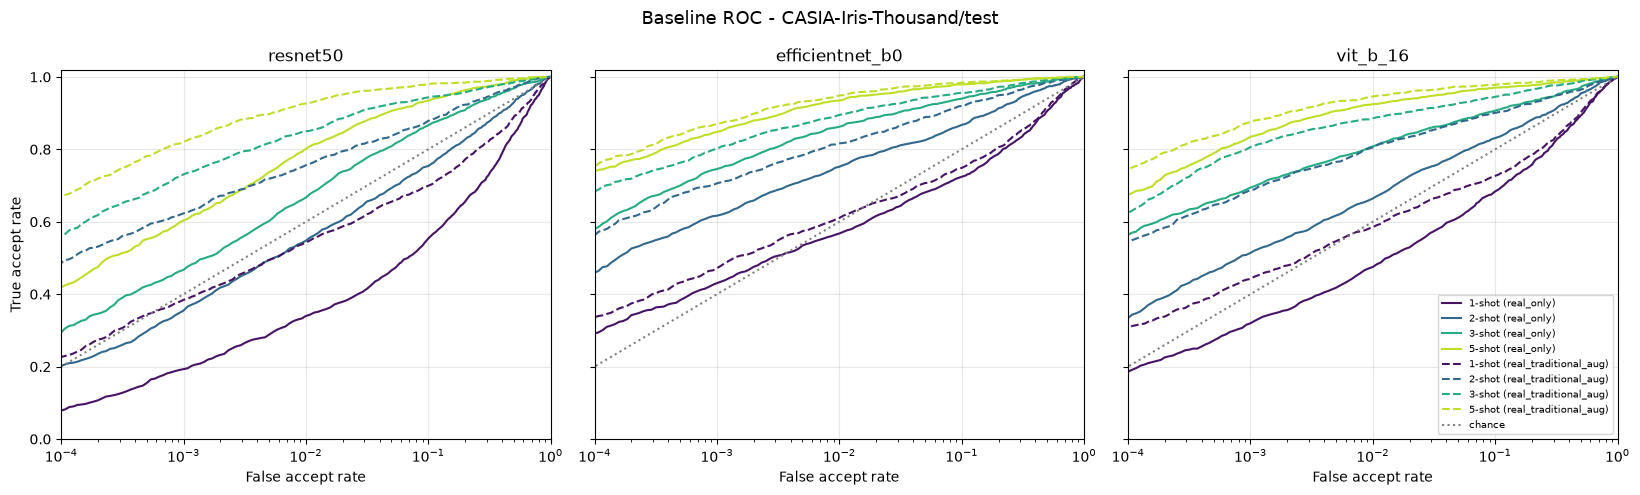

Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\baseline_recognition\baseline_roc_CASIA-Iris-Thousand__test.png


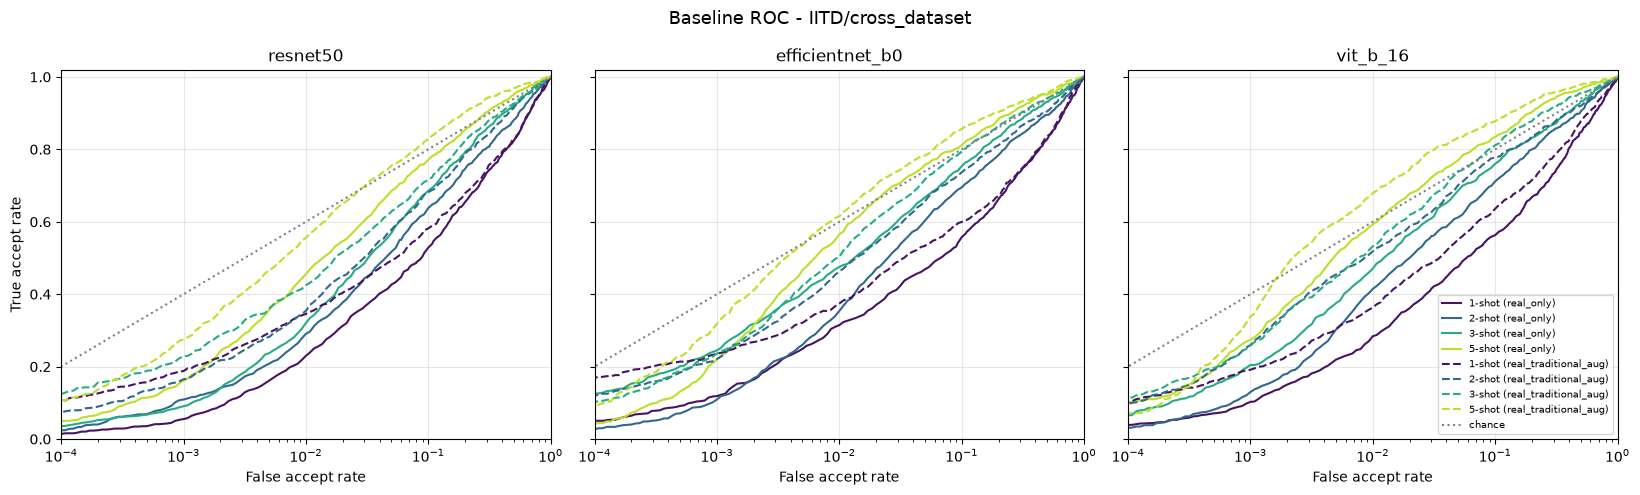

Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\baseline_recognition\baseline_roc_IITD__cross_dataset.png


In [19]:
# ============================================================
# 16a. ROC curves
# ============================================================

headline_sets = sorted(results.loc[results["kind"].isin(["within_dataset_test", "cross_dataset"]), "eval_set"].unique())
backbones_present = [b for b in BACKBONES if b in set(results["backbone"])]
shots_present = sorted(results["shot"].unique())
variants_present = [v for v in VARIANTS if v in set(results["variant"])]
colors = dict(zip(shots_present, plt.cm.viridis(np.linspace(0.05, 0.9, len(shots_present)))))
line_styles = dict(zip(variants_present, ["-", "--"]))

roc_mean = roc_points.groupby(["variant", "backbone", "shot", "eval_set", "fpr"], as_index=False)["tpr"].mean()

for eval_set in headline_sets:
    fig, axes = plt.subplots(1, len(backbones_present), figsize=(5.5 * len(backbones_present), 5), sharey=True)
    axes = np.atleast_1d(axes)

    for ax, backbone in zip(axes, backbones_present):
        for variant in variants_present:
            for shot in shots_present:
                curve = roc_mean[(roc_mean["eval_set"] == eval_set) & (roc_mean["backbone"] == backbone)
                                 & (roc_mean["variant"] == variant) & (roc_mean["shot"] == shot)]
                curve = curve[curve["fpr"] > 0]
                if len(curve):
                    ax.plot(curve["fpr"], curve["tpr"], line_styles[variant], color=colors[shot],
                            label=f"{shot}-shot ({variant})")

        ax.plot([1e-5, 1], [1e-5, 1], ":", color="gray", label="chance")
        ax.set_xscale("log")
        ax.set_xlim(1e-4, 1)
        ax.set_ylim(0, 1.02)
        ax.set_title(backbone)
        ax.set_xlabel("False accept rate")
        ax.grid(alpha=0.3)

    axes[0].set_ylabel("True accept rate")
    axes[-1].legend(fontsize=7, loc="lower right")
    plt.suptitle(f"Baseline ROC - {eval_set}", fontsize=13)
    plt.tight_layout()

    roc_path = RESULTS_DIR / f"baseline_roc_{safe_name(eval_set)}.png"
    plt.savefig(roc_path, dpi=200, bbox_inches="tight")
    plt.show()
    print("Saved:", roc_path)

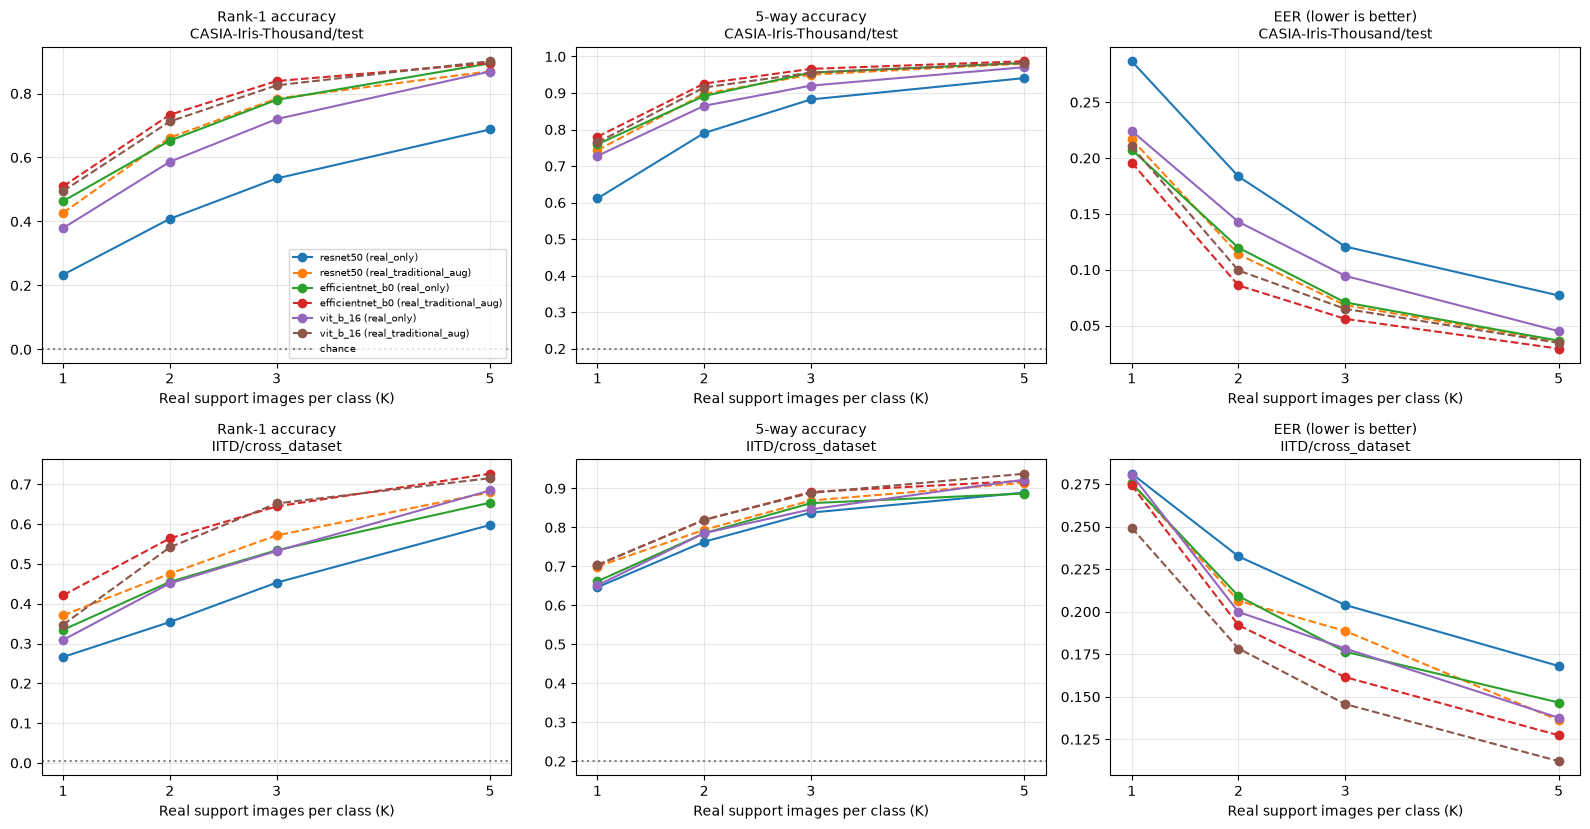

Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\baseline_recognition\baseline_metrics_vs_shots.png


In [20]:
# ============================================================
# 16b. Metrics versus number of shots
# ============================================================

metric_panels = [("rank1_acc_mean", "Rank-1 accuracy"), ("acc_5way_mean", f"{EPISODE_WAY}-way accuracy"), ("eer_mean", "EER (lower is better)")]

fig, axes = plt.subplots(len(headline_sets), 3, figsize=(16, 4.2 * len(headline_sets)), squeeze=False)

for row, eval_set in enumerate(headline_sets):
    subset = summary[summary["eval_set"] == eval_set]

    for col, (column, title) in enumerate(metric_panels):
        ax = axes[row, col]

        for backbone in backbones_present:
            for variant in variants_present:
                line = subset[(subset["backbone"] == backbone) & (subset["variant"] == variant)].sort_values("shot")
                if len(line):
                    ax.plot(line["shot"], line[column], marker="o", linestyle=line_styles[variant],
                            label=f"{backbone} ({variant})")

        if column != "eer_mean" and len(subset):
            ax.axhline(subset["chance_rank1"].iloc[0] if column == "rank1_acc_mean" else 1.0 / EPISODE_WAY,
                       color="gray", linestyle=":", label="chance")

        ax.set_xticks(shots_present)
        ax.set_xlabel("Real support images per class (K)")
        ax.set_title(f"{title}\n{eval_set}", fontsize=10)
        ax.grid(alpha=0.3)

axes[0, 0].legend(fontsize=7)
plt.tight_layout()

shots_plot_path = RESULTS_DIR / "baseline_metrics_vs_shots.png"
plt.savefig(shots_plot_path, dpi=200, bbox_inches="tight")
plt.show()
print("Saved:", shots_plot_path)

## 17. Baseline sanity checks

A baseline that is accidentally broken makes any later improvement meaningless, so the results are checked before they are handed on:

- every planned run finished and passed the leakage assertions,
- training actually reduced the loss,
- pretrained weights were loaded (a warning, not a failure, if not),
- the test results are clearly above chance.

In [21]:
# ============================================================
# 17. Sanity checks
# ============================================================

checks = []


def add_check(name, passed, details="", critical=True):
    checks.append({"check": name, "passed": bool(passed), "critical": critical, "details": details})
    status = "PASS" if passed else ("FAIL" if critical else "WARN")
    print(f"[{status}] {name}" + (f"  ({details})" if details else ""))


expected_ids = {make_run_id(v, b, s, sd) for (v, b, s, sd) in plan}
missing_runs = expected_ids - set(runs_table["run_id"])
add_check("all planned runs are present", not missing_runs, f"{len(missing_runs)} missing")
add_check("every run passed the train/evaluation leakage assertions", bool(runs_table["leakage_checks_passed"].all()))

not_decreasing = runs_table[runs_table["final_train_loss"] >= runs_table["initial_train_loss"]]
add_check("training loss decreased in every run", len(not_decreasing) == 0,
          f"{len(not_decreasing)} run(s) did not improve")

add_check("ImageNet weights were loaded in every run", bool(runs_table["pretrained_loaded"].all()) or not USE_PRETRAINED,
          f"{int((~runs_table['pretrained_loaded']).sum())} run(s) used random initialisation", critical=False)
add_check("a validation set was used to select the epoch in every run", bool(runs_table["selection_pool"].notna().all()),
          critical=False)

test_rows = results[results["kind"] == "within_dataset_test"]
near_chance = test_rows[test_rows["rank1_acc"] <= 2 * test_rows["chance_rank1"]]
add_check("test Rank-1 is more than twice chance everywhere", len(near_chance) == 0,
          f"{len(near_chance)} of {len(test_rows)} results are near chance", critical=False)

closed_rows = results[results["kind"] == "train_closed_set_diagnostic"]
if len(closed_rows):
    add_check("training identities are recognised better than unseen test identities",
              bool((closed_rows.groupby("run_id")["rank1_acc"].first() >= test_rows.groupby("run_id")["rank1_acc"].first().reindex(closed_rows["run_id"].unique())).mean() >= 0.5),
              "expected: seen people are easier than unseen people", critical=False)

sanity_report = pd.DataFrame(checks)
sanity_report.to_csv(RESULTS_DIR / "baseline_sanity_checks.csv", index=False)
print("\nSaved:", RESULTS_DIR / "baseline_sanity_checks.csv")

critical_failures = sanity_report[(~sanity_report["passed"]) & sanity_report["critical"]]
failed_names = list(critical_failures["check"])
assert len(critical_failures) == 0, f"Critical baseline checks failed: {failed_names}"
print("\nBaseline sanity checks completed with no critical failures.")

[PASS] all planned runs are present  (0 missing)
[PASS] every run passed the train/evaluation leakage assertions
[PASS] training loss decreased in every run  (0 run(s) did not improve)
[PASS] ImageNet weights were loaded in every run  (0 run(s) used random initialisation)
[PASS] a validation set was used to select the epoch in every run
[PASS] test Rank-1 is more than twice chance everywhere  (0 of 24 results are near chance)
[WARN] training identities are recognised better than unseen test identities  (expected: seen people are easier than unseen people)

Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\baseline_recognition\baseline_sanity_checks.csv

Baseline sanity checks completed with no critical failures.


## 18. Final outputs

At the end of Notebook 07, the project should contain:

```text
results/baseline_recognition/
├── runs/                          one JSON record per training run
├── baseline_accuracy.csv          Baseline Accuracy
├── baseline_roc.csv               Baseline ROC
├── baseline_eer.csv               Baseline EER
├── baseline_results.csv           every metric, every run, every evaluation set
├── baseline_summary.csv           averaged over seeds
├── baseline_runs.csv              training facts per run
├── training_history.csv           loss and validation curves
├── baseline_sanity_checks.csv
├── baseline_roc_<evaluation set>.png
└── baseline_metrics_vs_shots.png

checkpoints/baseline_recognition/<run_id>.pt     best-validation weights per run
pretrained_models/torch_hub/                      downloaded ImageNet weights
```

In [22]:
# ============================================================
# 18. Final output listing
# ============================================================

print("Notebook 07 output directory:")
print(RESULTS_DIR)

print("\nTop-level generated files:")
for path in sorted(RESULTS_DIR.iterdir()):
    if path.is_file():
        print(f"- {path.name}")

print(f"\nRun records: {len(list(RUNS_DIR.glob('*.json')))} | checkpoints: {len(list(CHECKPOINT_DIR.glob('*.pt')))}")
print("\nNotebook 07 completed.")

Notebook 07 output directory:
E:\Research\LargeScale_Synthetic_Iris_Generation\results\baseline_recognition

Top-level generated files:
- baseline_accuracy.csv
- baseline_eer.csv
- baseline_metrics_vs_shots.png
- baseline_results.csv
- baseline_roc.csv
- baseline_roc_CASIA-Iris-Thousand__test.png
- baseline_roc_IITD__cross_dataset.png
- baseline_runs.csv
- baseline_sanity_checks.csv
- baseline_summary.csv
- training_history.csv

Run records: 24 | checkpoints: 24

Notebook 07 completed.


## 19. What this notebook hands to the rest of the project

```text
Notebook 06                Notebook 07                       Notebooks 08 - 17
Few-shot dataset  --->     Baseline (real data only)  --->   Synthetic-data models are
(train/val/test,           Accuracy, ROC, EER                 compared against these numbers
 1/2/3/5-shot)
```

### How the baseline is used

1. **"Real only" and "traditional augmentation" rows** of the final comparison tables (Notebook 17) come from `baseline_summary.csv` (`variant = real_only` and `real_traditional_aug`).
2. **The proposed method must be scored with the identical protocol**: the same `evaluate_embeddings` function, the same `EVAL_SEED` (so the same 5-way episodes), the same gallery / probe construction, and the same evaluation sets. Copy the metrics cell (section 8) unchanged into Notebooks 13, 14 and 16 rather than rewriting it.
3. **Train the synthetic-data models with the same hyperparameters** (backbone, ArcFace settings, schedule, selection rule) so the only change is the training data. Triplet and Center losses are added only in the final model of Notebook 13; the ArcFace-only result stays the like-for-like comparison.
4. **Cross-dataset (Notebook 14)**: `<IITD>/cross_dataset` rows already give the CASIA-to-IITD baseline.
5. **Statistical testing (Notebook 18)**: use `SEEDS` with more than one value to obtain a spread over training randomness; remember the support draw itself is fixed by Notebook 06 (change its `RANDOM_SEED` to study that source of variance).

### Rules that keep the comparison honest

- Synthetic images may enter **training** only. Validation and test stay real, exactly as defined in Notebook 06.
- Do not tune hyperparameters on `test` or on the cross-dataset set; use `val`.
- Report the configuration fingerprint (`CONFIG_HASH`) and seed with every number.